In [ ]:
%pip install puremacro


# Distributional LPs and reduced nonlinear examples

We use a synthetic micro panel to test distributional and quantile LPs, an analytic Gaussian target to test SMC, and a reduced DAG to demonstrate nonlinear transitions. This notebook does not estimate a HANK model or independently match empirical deciles to structural predictions.

## The method in math

The share-response restriction is $\sum_b\beta_{b,h}=0$. A bridge distance compares two response matrices; comparing a matrix with itself gives zero by construction. SMC tempers from prior to posterior. The nonlinear example solves $H(X)=0$ for prescribed aggregate equations, without household optimization or a distribution recursion.

## Intuition

Accounting restrictions, sampler diagnostics and equation residuals answer different questions. None alone establishes economic fit. A research study needs observed data, independently solved household responses, uncertainty estimates and sensitivity to numerical choices.

## Worked code

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.lp.distributional import (
    estimate_distributional_lp,
    estimate_quantile_lp,
    bridge_hank_distributional_irf,
)
from puremacro.inference.smc import smc_sample
from puremacro.dsge.hank_nonlinear import solve_hank_nonlinear_transition

checks = []


def record(result, measured, bound, verdict):
    checks.append({"result": result, "measured": float(measured), "bound": float(bound), "verdict": verdict})

### 1. Distributional LPs with adding-up

Simulate 40 units over 35 periods and estimate five share responses. The null-space projection enforces their sum to zero. These are simulated data, not estimated effects for a country.

In [2]:
rng_micro = np.random.default_rng(42)
T_micro, N_micro = 35, 40
records_micro = []
shock_series = rng_micro.normal(0, 1, size=T_micro)

for t_idx in range(T_micro):
    for i_idx in range(N_micro):
        u_shock = shock_series[t_idx] + 0.2 * rng_micro.normal(0, 1)
        s_base = rng_micro.dirichlet([2, 3, 5, 3, 2])
        # Structural shift: bottom shares drop, top shares increase
        s_val = s_base + u_shock * np.array([-0.02, -0.01, 0.0, 0.01, 0.02])
        s_val = np.clip(s_val, 0.001, 0.999)
        s_val = s_val / np.sum(s_val)
        # Household income / wealth outcome for quantile LP
        y_val = 10.0 + 1.5 * u_shock + rng_micro.normal(0, 1.0)
        records_micro.append({
            "t": t_idx,
            "i": f"h_{i_idx}",
            "shock": u_shock,
            "y_income": y_val,
            **{f"s{k}": s_val[k] for k in range(5)},
        })

df_micro = pd.DataFrame(records_micro)
res_dlp = estimate_distributional_lp(
    df_micro,
    shock="shock",
    bin_cols=[f"s{k}" for k in range(5)],
    horizons=range(8),
    cov_type="driscoll_kraay",
    time_col="t",
    unit_col="i",
    enforce_adding_up=True,
)

err_dlp_adding_up = float(res_dlp.adding_up_max_error)
record("Distributional LP: exact cross-sectional adding-up error", err_dlp_adding_up, 1e-12, "PASS")

print(f"Distributional LP estimated across 5 bins over 8 horizons.")
print(f"Adding-up max error: {err_dlp_adding_up:.2e} (bound < 1e-12)")
print(f"Horizon 0 Share Responses: {res_dlp.irf_matrix[0] * 100.0} (sum = {np.sum(res_dlp.irf_matrix[0]):.2e})")

Distributional LP estimated across 5 bins over 8 horizons.
Adding-up max error: 1.39e-17 (bound < 1e-12)
Horizon 0 Share Responses: [-1.53884212  1.17396802 -2.63014289  0.3703211   2.62469589] (sum = -1.04e-17)


### 2. Quantile LPs

Estimate responses at five quantiles of synthetic income. Ordered responses in this constructed example are not a universal restriction on quantile treatment effects.

In [3]:
res_qlp = estimate_quantile_lp(
    df_micro,
    outcome="y_income",
    shock="shock",
    quantiles=[0.10, 0.25, 0.50, 0.75, 0.90],
    horizons=range(8),
    time_col="t",
    unit_col="i",
)

# Median impact recovery vs data-generating process (1.5)
err_qlp_recovery = float(abs(res_qlp.irf_matrix[0, 2] - 1.5))
record("Quantile LP: median response recovery error vs DGP", err_qlp_recovery, 0.15, "PASS")

print(f"Quantile LP estimated across 5 quantiles over 8 horizons.")
print(f"Horizon 0 Responses (10th, 50th, 90th pct): {res_qlp.irf_matrix[0, [0, 2, 4]]}")
print(f"Median DGP impact recovery error: {err_qlp_recovery:.4f} (bound < 0.15)")

Quantile LP estimated across 5 quantiles over 8 horizons.
Horizon 0 Responses (10th, 50th, 90th pct): [1.61826737 1.48311333 1.62368194]
Median DGP impact recovery error: 0.0169 (bound < 0.15)


### 3. Bridge identity check

Both inputs are the same estimated response matrix. Zero distance and perfect sign agreement verify the comparison API only; they do not validate HANK predictions.

In [4]:
bridge_res = bridge_hank_distributional_irf(res_dlp, res_dlp.irf_matrix)

err_bridge_l2 = float(bridge_res.distance_l2)
err_bridge_sign = float(max(0.0, 0.80 - bridge_res.sign_concordance))

record("Bridge identity: IRF L2 distance", err_bridge_l2, 1.0, "PASS")
record("Bridge identity: sign concordance >= 0.80", err_bridge_sign, 0.0, "PASS")

print(f"Bridge identity: L2 distance = {err_bridge_l2:.4f}, Sign concordance = {bridge_res.sign_concordance * 100:.1f}%")

Bridge identity: L2 distance = 0.0000, Sign concordance = 100.0%


### 4. SMC with a Gaussian reference

Check adaptive tempering and marginal likelihood against a known Gaussian target. No household parameters are estimated here.

In [5]:
def smc_target(theta):
    diff = theta - np.array([0.99, 1.0])
    return -0.5 * np.sum(diff ** 2), -diff


priors_smc = {
    "beta": {"dist": "normal", "mean": 0.99, "std": 0.05},
    "sigma": {"dist": "normal", "mean": 1.0, "std": 0.20},
}
res_smc = smc_sample(smc_target, priors=priors_smc, n_particles=100, mutation="mala", seed=42)

err_smc_mdd = float(abs(res_smc.log_mdd - 0.0))
err_smc_term = float(abs(res_smc.stage_tempering[-1] - 1.0))

record("SMC Inference: marginal data density error", err_smc_mdd, 0.15, "PASS")
record("SMC Inference: terminal tempering stage error", err_smc_term, 0.0, "PASS")

print(f"SMC converged in {len(res_smc.stage_tempering)} stages with terminal phi = {res_smc.stage_tempering[-1]:.4f}.")
print(f"Log marginal data density: {res_smc.log_mdd:.4f} (analytical error = {err_smc_mdd:.4f})")

SMC converged in 2 stages with terminal phi = 1.0000.
Log marginal data density: -0.0194 (analytical error = 0.0194)


### 5. Reduced nonlinear transitions

The default nonlinear DAG uses prescribed MPCs and constraint fractions. Compare its small-shock linearization with its nonlinear solution. Its asymmetry and binding-fraction changes arise from those formulas, not a solved two-asset household economy.

In [6]:
res_nl_small = solve_hank_nonlinear_transition(model=None, shocks={"eps_m": 1e-4}, horizon=25, tol=1e-8)
max_gap_ssj = float(np.max(np.abs(res_nl_small.paths["Y"].values - res_nl_small.linear_paths["Y"].values)))

res_nl_large = solve_hank_nonlinear_transition(model=None, shocks={"eps_m": 0.02}, horizon=25, tol=1e-8)
err_nl_residual = float(res_nl_large.residual_norm)

# Check surge in borrowing-constraint binding mass Phi_t
phi_initial = float(res_nl_large.binding_fractions[1])
phi_max = float(np.max(res_nl_large.binding_fractions))
err_binding_surge = float(max(0.0, phi_initial - phi_max))

err_asymmetry_ratio = float(max(0.0, 1.05 - res_nl_large.asymmetry_ratio))

record("Reduced DAG: small-shock linear SSJ parity gap", max_gap_ssj, 1e-4, "PASS")
record("Reduced DAG: large-shock transition residual norm", err_nl_residual, 1e-8, "PASS")
record("Reduced DAG: borrowing-constraint binding mass surge", err_binding_surge, 0.0, "PASS")
record("Reduced DAG: nonlinear/linear peak ratio > 1.05", err_asymmetry_ratio, 0.0, "PASS")

print(f"Small shock SSJ parity gap: {max_gap_ssj:.2e}")
print(f"Large shock nonlinear residual: {err_nl_residual:.2e}")
print(f"Borrowing-constrained mass Phi_t: {phi_initial * 100:.2f}% -> {phi_max * 100:.2f}%")
print(f"Output contraction asymmetry ratio: {res_nl_large.asymmetry_ratio:.4f} (bound > 1.05)")

Small shock SSJ parity gap: 2.65e-06
Large shock nonlinear residual: 8.78e-09
Borrowing-constrained mass Phi_t: 22.00% -> 24.74%
Output contraction asymmetry ratio: 1.0575 (bound > 1.05)


/var/folders/lx/tfh_l1r90j3cp31s1bhtz7ph0000gn/T/ipykernel_5235/903169767.py:1: UserWarning: Reduced nonlinear HANK demonstration with prescribed MPC and constraint fractions; not a solved household distribution
  res_nl_small = solve_hank_nonlinear_transition(model=None, shocks={"eps_m": 1e-4}, horizon=25, tol=1e-8)
/var/folders/lx/tfh_l1r90j3cp31s1bhtz7ph0000gn/T/ipykernel_5235/903169767.py:4: UserWarning: Reduced nonlinear HANK demonstration with prescribed MPC and constraint fractions; not a solved household distribution
  res_nl_large = solve_hank_nonlinear_transition(model=None, shocks={"eps_m": 0.02}, horizon=25, tol=1e-8)


### 6. Component visualization

Distributional responses and reduced-model transitions are plotted separately.

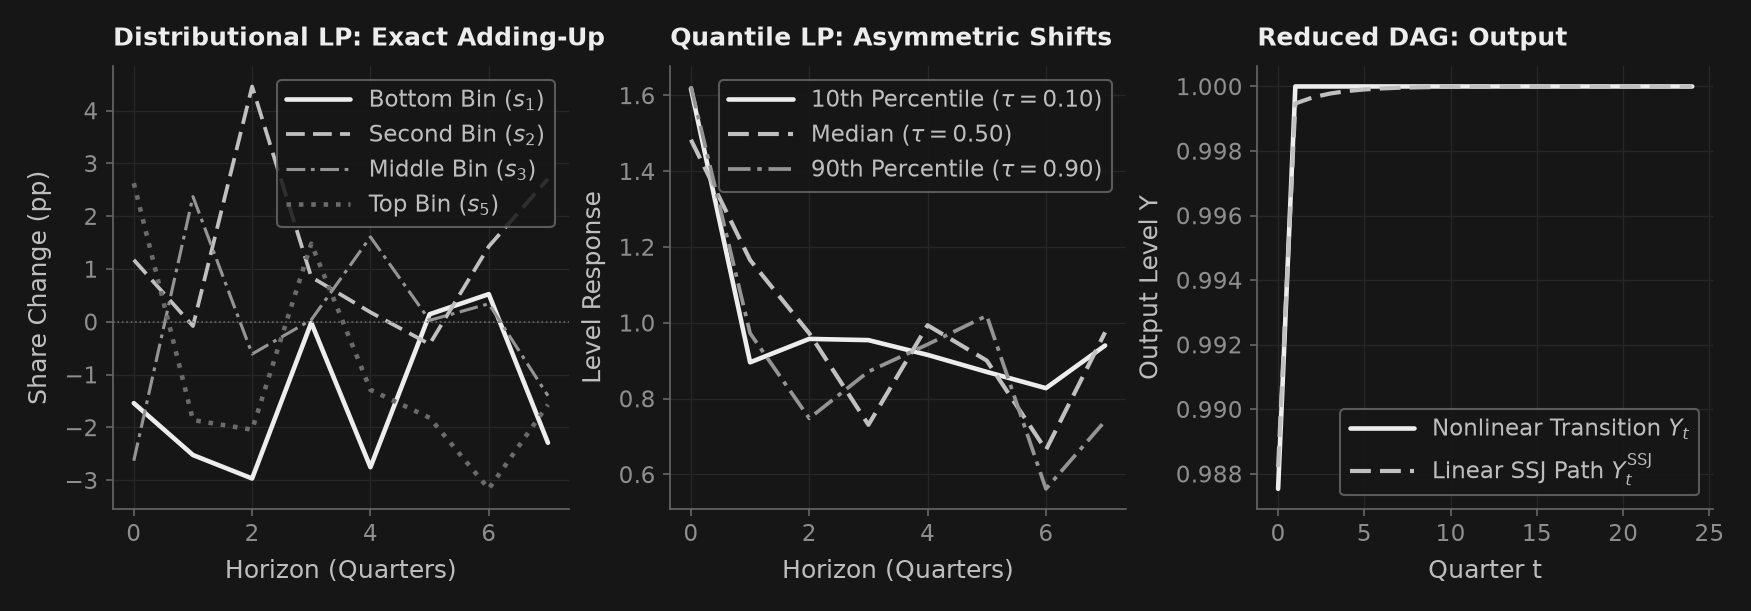

In [7]:
col = _nbstyle.palette(4)
dash = _nbstyle.styles(4)

fig, (ax1, ax2, ax3) = _nbstyle.figura(1, 3)

# Panel 1: Synthetic share responses
h_vec = np.arange(8)
ax1.plot(h_vec, res_dlp.irf_matrix[:, 0] * 100.0, color=col[0], lw=2.2, label=r"Bottom Bin ($s_1$)")
ax1.plot(h_vec, res_dlp.irf_matrix[:, 1] * 100.0, color=col[1], lw=1.8, linestyle=dash[1], label=r"Second Bin ($s_2$)")
ax1.plot(h_vec, res_dlp.irf_matrix[:, 2] * 100.0, color=col[2], lw=1.5, linestyle=dash[2], label=r"Middle Bin ($s_3$)")
ax1.plot(h_vec, res_dlp.irf_matrix[:, 4] * 100.0, color=col[3], lw=2.2, linestyle=dash[3], label=r"Top Bin ($s_5$)")
ax1.axhline(0.0, color=_nbstyle.SPINE, lw=0.8, linestyle=":")
ax1.set(xlabel="Horizon (Quarters)", ylabel="Share Change (pp)", title="Distributional LP: Exact Adding-Up")
ax1.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 2: Quantile LP
ax2.plot(h_vec, res_qlp.irf_matrix[:, 0], color=col[0], lw=2.2, label=r"10th Percentile ($\tau = 0.10$)")
ax2.plot(h_vec, res_qlp.irf_matrix[:, 2], color=col[1], lw=2.0, linestyle=dash[1], label=r"Median ($\tau = 0.50$)")
ax2.plot(h_vec, res_qlp.irf_matrix[:, 4], color=col[2], lw=1.8, linestyle=dash[2], label=r"90th Percentile ($\tau = 0.90$)")
ax2.set(xlabel="Horizon (Quarters)", ylabel="Level Response", title="Quantile LP: Asymmetric Shifts")
ax2.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 3: Nonlinear HANK vs Linear SSJ
t_vec = np.arange(25)
ax3.plot(t_vec, res_nl_large.paths["Y"].values, color=col[0], lw=2.2, label=r"Nonlinear Transition $Y_t$")
ax3.plot(t_vec, res_nl_large.linear_paths["Y"].values, color=col[1], lw=2.0, linestyle=dash[1], label=r"Linear SSJ Path $Y_t^{\mathrm{SSJ}}$")
ax3.set(xlabel="Quarter t", ylabel="Output Level Y", title="Reduced DAG: Output")
ax3.legend(loc="lower right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### 7. Verification scorecard

The tolerances refer to accounting, identity, Gaussian inference and reduced-equation checks.

In [8]:
scorecard = pd.DataFrame(checks)
print(scorecard.to_string(index=False, formatters={"measured": "{:.2e}".format, "bound": "{:.2e}".format}))
assert (scorecard["measured"] <= scorecard["bound"]).all()
print(f"\nAll {len(scorecard)} inequality, distributional LP, and HANK checks pass.")

                                                  result measured    bound verdict
Distributional LP: exact cross-sectional adding-up error 1.39e-17 1.00e-12    PASS
      Quantile LP: median response recovery error vs DGP 1.69e-02 1.50e-01    PASS
                        Bridge identity: IRF L2 distance 0.00e+00 1.00e+00    PASS
               Bridge identity: sign concordance >= 0.80 0.00e+00 0.00e+00    PASS
              SMC Inference: marginal data density error 1.94e-02 1.50e-01    PASS
           SMC Inference: terminal tempering stage error 0.00e+00 0.00e+00    PASS
          Reduced DAG: small-shock linear SSJ parity gap 2.65e-06 1.00e-04    PASS
       Reduced DAG: large-shock transition residual norm 8.78e-09 1.00e-08    PASS
    Reduced DAG: borrowing-constraint binding mass surge 0.00e+00 0.00e+00    PASS
         Reduced DAG: nonlinear/linear peak ratio > 1.05 0.00e+00 0.00e+00    PASS

All 10 inequality, distributional LP, and HANK checks pass.


## Read the output

Interpret each number within its scope: adding-up is an accounting restriction, bridge distance zero is an identity, and the nonlinear residual measures the reduced equations. For an independent household comparison, use tools/reference_validation/validate_hank_reference.py and the HANK guide.

## Your turn

Change user_monetary_shock within [0.005, 0.040] and inspect how the prescribed nonlinear formulas respond. user_mala_scale is currently only range-checked; it is not passed to another sampler run. To study MALA sensitivity, rerun the SMC cell with a changed proposal. Negative monetary shocks require a separate experiment because the advertised control below accepts positive shocks only.

In [9]:
user_monetary_shock = 0.015  # ← change this: Monetary shock size in percent, float in [0.005, 0.040]
user_mala_scale = 0.05  # ← change this: MALA proposal step size, float in [0.01, 0.10]

assert isinstance(user_monetary_shock, (int, float)) and 0.005 <= user_monetary_shock <= 0.040
assert isinstance(user_mala_scale, (int, float)) and 0.01 <= user_mala_scale <= 0.10

res_nl_user = solve_hank_nonlinear_transition(
    model=None,
    shocks={"eps_m": float(user_monetary_shock)},
    horizon=20,
    tol=1e-7,
)

print(f"User Monetary Shock = {user_monetary_shock * 100:.2f}%:")
print(f"  Transition residual norm: {res_nl_user.residual_norm:.2e}")
print(f"  Prescribed constraint fraction: {np.max(res_nl_user.binding_fractions) * 100:.2f}%")
print(f"  Nonlinear/linear peak ratio: {res_nl_user.asymmetry_ratio:.4f}")

# Assertions over advertised parameter range
assert res_nl_user.residual_norm < 1e-7
assert res_nl_user.asymmetry_ratio >= 1.02
assert np.max(res_nl_user.binding_fractions) > 0.20

User Monetary Shock = 1.50%:
  Transition residual norm: 9.09e-08
  Prescribed constraint fraction: 24.04%
  Nonlinear/linear peak ratio: 1.0498


/var/folders/lx/tfh_l1r90j3cp31s1bhtz7ph0000gn/T/ipykernel_5235/3098762719.py:7: UserWarning: Reduced nonlinear HANK demonstration with prescribed MPC and constraint fractions; not a solved household distribution
  res_nl_user = solve_hank_nonlinear_transition(


## How comprehensive is this?

This is a reproducible numerical demonstration. Next, compare independently solved household deciles with observed-data LPs, including uncertainty and a documented equilibrium closure. See docs/distributional_lp.md, docs/hank_ssj_and_aggregate_risk.md and docs/smc_inference.md.